# BHGA with its own charging decoder vs. BHGA with SS-FR-FLA

The full BHGA metaheuristic (Feng et al., 2024, configuration `-mix 12116`, BHGA-SP) is run twice per instance and seed:

| Key | Charging decoder inside BHGA |
|---|---|
| `vanilla` | BHGA's own `focusEnumeration` |
| `ss_fr_fla` | SS-FR-FLA (`BatteryDecode`, at most one station per edge) |

Everything else (genetic operators, local search, seeds, stopping rule) is identical. Both variants stop after the same number of iterations without improvement, so the comparison is at equal search effort. Runtime is reported separately.

Data comes from `scripts/collect_bhga_comparison.py`.

In [2]:
import math
import json
import os
import re
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns
from IPython.display import display

plt.rcParams.update({
    "font.family":        "serif",
    "mathtext.fontset":   "cm",
    "font.size":          6,
    "axes.labelsize":     7,
    "xtick.labelsize":    5,
    "ytick.labelsize":    5,
    "figure.dpi":         200,
    "savefig.dpi":        600,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.02,
})

RESULTS_PATH = Path(os.environ.get("BHGA_RESULTS", "../results/bhga_comparison.jsonl"))
OUT_DIR = Path("../.output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
DECODERS = ["vanilla", "ss_fr_fla"]
DECODER_LABELS = {"vanilla": "BHGA", "ss_fr_fla": "BHGA + SS-FR-FLA"}
DECODER_COLORS = {"vanilla": "#984ea3", "ss_fr_fla": "#4daf4a"}

# Two runs whose costs differ by less than this (relative) count as a tie.
TIE_TOL = 1e-6
# BHGA charges an energy-infeasible route INT_MAX; such costs in the
# search progress are not real distances.
INFEASIBLE_COST = 2**31 - 1

# Reference cost per instance for the gap columns. By default this is the best
# cost found by any run in this experiment. The OPTIMAL_VALUE field in the
# .evrp files is not a best-known value (runs beat it), so it is not used.
# Literature best-known values can be put here to override it.
REFERENCE_OVERRIDE = {}


def _style_ax(ax):
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.5)
    ax.spines["bottom"].set_linewidth(0.5)
    ax.tick_params(width=0.5, length=3, direction="out")


def customer_count(name):
    return int(re.search(r"-n(\d+)-", name).group(1))


def sorted_instances(names):
    return sorted(set(names), key=customer_count)


def sign_test(wins, losses):
    # Two-sided exact sign test, ties dropped.
    n = wins + losses
    if n == 0:
        return float("nan")
    k = min(wins, losses)
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2**n)

## Load results

In [4]:
with open(RESULTS_PATH) as f:
    records = [json.loads(line) for line in f if line.strip()]

df = pd.DataFrame(records)
configs = df.groupby(["nb_iter", "mix"]).size()
print("Runs per (nb_iter, mix):")
print(configs.to_string())

# Analyse the configuration with the most runs.
NB_ITER, MIX = configs.idxmax()
df = df[(df.nb_iter == NB_ITER) & (df.mix == MIX)].copy()
INSTANCES = sorted_instances(df.instance)
REF = {name: REFERENCE_OVERRIDE.get(name, df[df.instance == name].cost.min()) for name in INSTANCES}

assert df.valid.all(), "some final solutions failed validation"
assert df.energy_feasible.all(), "some final solutions are not energy feasible"

seed_counts = df.pivot_table(index="instance", columns="decoder", values="seed", aggfunc="count").reindex(INSTANCES)
print(f"\nnb_iter={NB_ITER}, mix={MIX}; seeds per instance and decoder:")
display(seed_counts)

df["gap_ref"] = 100 * (df.cost - df.instance.map(REF)) / df.instance.map(REF)
df["decoder_share"] = 100 * df.charge_ns / 1e9 / df.elapsed_s
df["us_per_call"] = df.charge_ns / df.charge_calls / 1e3

# Seed-paired view: one row per (instance, seed) with both decoders.
paired = df.pivot_table(index=["instance", "seed"], columns="decoder", values="cost").dropna()
paired["diff_pct"] = 100 * (paired.ss_fr_fla - paired.vanilla) / paired.vanilla
print(f"{len(paired)} seed-paired runs")

Runs per (nb_iter, mix):
nb_iter  mix  
30000    12116    224

nb_iter=30000, mix=12116; seeds per instance and decoder:


decoder,ss_fr_fla,vanilla
instance,,
E-n22-k4,16,16
E-n23-k3,16,16
E-n30-k3,16,16
E-n33-k4,16,16
E-n51-k5,16,16
E-n76-k7,16,16
E-n101-k8,16,16


112 seed-paired runs


## Solution quality

Per instance: best and mean ± std of the final cost over seeds, and the mean gap to the reference cost (*Ref*: the best cost found by any run, unless overridden in `REFERENCE_OVERRIDE`). The paired columns compare the two variants seed by seed. **Δ** is the mean of (SS − vanilla)/vanilla; negative means SS-FR-FLA is better. **W/T/L** counts the seeds where SS-FR-FLA wins, ties or loses, and *p* is the two-sided sign test on W vs. L.

In [5]:
def build_quality_table():
    rows = []
    for name in INSTANCES + ["Aggregate"]:
        sub = df if name == "Aggregate" else df[df.instance == name]
        pair = paired if name == "Aggregate" else paired.loc[name]
        row = {"Instance": name, "Ref": "" if name == "Aggregate" else f"{REF[name]:.2f}"}
        for dec in DECODERS:
            d = sub[sub.decoder == dec]
            label = DECODER_LABELS[dec]
            if name == "Aggregate":
                row[f"{label} best"] = ""
                row[f"{label} mean ± std"] = ""
            else:
                row[f"{label} best"] = f"{d.cost.min():.2f}"
                row[f"{label} mean ± std"] = f"{d.cost.mean():.2f} ± {d.cost.std():.2f}"
            row[f"{label} gap Ref"] = f"{d.gap_ref.mean():.3f}%"

        rel = (pair.ss_fr_fla - pair.vanilla) / pair.vanilla
        wins, losses = int((rel < -TIE_TOL).sum()), int((rel > TIE_TOL).sum())
        ties = len(rel) - wins - losses
        row["Δ"] = f"{pair.diff_pct.mean():+.3f}%"
        row["W/T/L"] = f"{wins}/{ties}/{losses}"
        row["p"] = f"{sign_test(wins, losses):.3f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("Instance")


quality_table = build_quality_table()
quality_table.to_csv(OUT_DIR / "bhga_quality.csv")
display(quality_table)

,Ref,BHGA best,BHGA mean ± std,BHGA gap Ref,BHGA + SS-FR-FLA best,BHGA + SS-FR-FLA mean ± std,BHGA + SS-FR-FLA gap Ref,Δ,W/T/L,p
Instance,,,,,,,,,,
E-n22-k4,384.68,384.68,384.68 ± 0.00,0.000%,384.68,384.68 ± 0.00,0.000%,+0.000%,0/16/0,nan
E-n23-k3,571.95,571.95,571.95 ± 0.00,0.000%,571.95,571.95 ± 0.00,0.000%,-0.000%,0/16/0,nan
E-n30-k3,509.47,509.47,509.47 ± 0.00,0.000%,509.47,509.47 ± 0.00,0.000%,+0.000%,0/16/0,nan
E-n33-k4,840.15,840.15,840.15 ± 0.00,0.000%,840.15,840.15 ± 0.00,0.000%,+0.000%,0/16/0,nan
E-n51-k5,529.90,529.90,529.90 ± 0.00,0.000%,529.90,529.90 ± 0.00,0.000%,+0.000%,0/16/0,nan
E-n76-k7,692.64,692.64,692.64 ± 0.00,0.000%,692.64,692.64 ± 0.00,0.000%,+0.000%,0/16/0,nan
E-n101-k8,834.22,834.22,836.39 ± 1.71,0.259%,834.22,835.47 ± 1.19,0.149%,-0.110%,9/2/5,0.424
Aggregate,,,,0.037%,,,0.021%,-0.016%,9/98/5,0.424


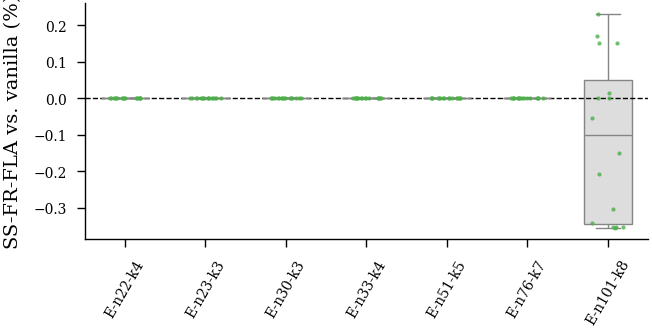

In [6]:
def plot_paired_differences(save_path=None):
    fig, ax = plt.subplots(figsize=(3.4, 1.8))
    data = paired.reset_index()
    order = INSTANCES
    sns.boxplot(data=data, x="instance", y="diff_pct", order=order, ax=ax, color="#dddddd",
                linewidth=0.5, fliersize=0, width=0.6)
    sns.stripplot(data=data, x="instance", y="diff_pct", order=order, ax=ax, color=DECODER_COLORS["ss_fr_fla"],
                  size=1.5, jitter=0.2, alpha=0.8)
    ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
    ax.set_xlabel("")
    ax.set_ylabel("SS-FR-FLA vs. vanilla (%)")
    ax.tick_params(axis="x", rotation=60)
    _style_ax(ax)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path)
    plt.show()


plot_paired_differences(OUT_DIR / "bhga_paired_diff.png")

## Search effort

Both variants get the same budget of iterations *without improvement*, so the total number of iterations depends on how long each keeps improving. Times are wall-clock seconds per run (one run per process). *Decoder share* is the part of the runtime spent in the charging decoder.

In [7]:
def build_effort_table():
    rows = []
    for name in INSTANCES:
        sub = df[df.instance == name]
        row = {"Instance": name}
        for dec in DECODERS:
            d = sub[sub.decoder == dec]
            label = DECODER_LABELS[dec]
            row[f"{label} iterations"] = f"{d.iterations.mean():.0f}"
            row[f"{label} time (s)"] = f"{d.elapsed_s.mean():.1f} ± {d.elapsed_s.std():.1f}"
            row[f"{label} decoder share"] = f"{d.decoder_share.mean():.0f}%"
            row[f"{label} µs/call"] = f"{d.us_per_call.mean():.2f}"
        v = sub[sub.decoder == "vanilla"].elapsed_s.mean()
        s = sub[sub.decoder == "ss_fr_fla"].elapsed_s.mean()
        row["time ratio"] = f"{s / v:.2f}×"
        rows.append(row)
    return pd.DataFrame(rows).set_index("Instance")


effort_table = build_effort_table()
effort_table.to_csv(OUT_DIR / "bhga_effort.csv")
display(effort_table)

,BHGA iterations,BHGA time (s),BHGA decoder share,BHGA µs/call,BHGA + SS-FR-FLA iterations,BHGA + SS-FR-FLA time (s),BHGA + SS-FR-FLA decoder share,BHGA + SS-FR-FLA µs/call,time ratio
Instance,,,,,,,,,
E-n22-k4,31450,4.3 ± 0.6,19%,0.56,31487,9.7 ± 1.3,63%,4.25,2.27×
E-n23-k3,30000,4.9 ± 1.5,33%,1.50,30000,10.8 ± 0.9,69%,6.88,2.21×
E-n30-k3,30000,9.9 ± 3.3,32%,1.35,30000,24.1 ± 6.0,72%,7.33,2.44×
E-n33-k4,38917,10.9 ± 1.8,28%,1.10,41700,30.1 ± 5.9,69%,6.99,2.77×
E-n51-k5,30000,12.2 ± 4.2,25%,1.32,30019,36.1 ± 4.2,72%,11.19,2.95×
E-n76-k7,30456,22.4 ± 6.5,27%,1.53,30256,64.5 ± 5.6,74%,12.07,2.87×
E-n101-k8,65071,57.8 ± 18.9,29%,1.61,70717,220.5 ± 83.3,76%,14.47,3.82×


## Convergence

Median (line) and interquartile range (band) over seeds of the best-so-far gap to *Ref*, against iterations and against CPU time. Curves start once every seed has a feasible solution.

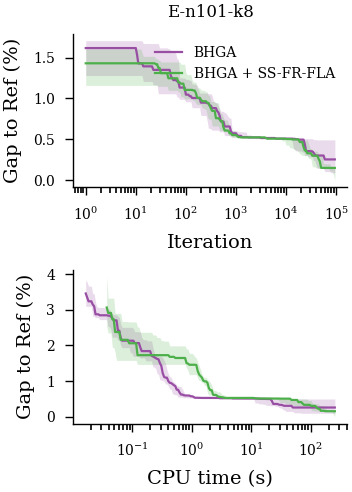

In [8]:
CONVERGENCE_INSTANCES = [n for n in ["E-n101-k8", "X-n351-k40", "X-n1001-k43"] if n in INSTANCES] or INSTANCES[-3:]


def best_so_far(progress, grid, axis):
    # progress: list of (iteration, cost, cpu_s); returns the best cost at each grid point.
    pts = [(p[axis], p[1]) for p in progress if p[1] < INFEASIBLE_COST]
    xs = np.array([x for x, _ in pts], dtype=float)
    ys = np.array([y for _, y in pts], dtype=float)
    idx = np.searchsorted(xs, grid, side="right") - 1
    out = np.full(len(grid), np.nan)
    out[idx >= 0] = ys[idx[idx >= 0]]
    return out


def plot_convergence(save_path=None):
    fig, axes = plt.subplots(2, len(CONVERGENCE_INSTANCES), figsize=(1.9 * len(CONVERGENCE_INSTANCES), 2.6),
                             squeeze=False)
    for col, name in enumerate(CONVERGENCE_INSTANCES):
        sub = df[df.instance == name]
        for row, (axis, xlabel) in enumerate([(0, "Iteration"), (2, "CPU time (s)")]):
            ax = axes[row][col]
            x_max = max(max(p[axis] for p in prog) for prog in sub.progress)
            x_min = 1 if axis == 0 else min((p[axis] for prog in sub.progress for p in prog if p[axis] > 0), default=1e-3)
            grid = np.geomspace(max(x_min, 1e-3), max(x_max, x_min * 10), 200)
            for dec in DECODERS:
                curves = np.array([best_so_far(prog, grid, axis) for prog in sub[sub.decoder == dec].progress])
                gaps = 100 * (curves - REF[name]) / REF[name]
                gaps[:, np.isnan(gaps).any(axis=0)] = np.nan
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", RuntimeWarning)
                    q25, med, q75 = np.nanpercentile(gaps, [25, 50, 75], axis=0)
                ax.plot(grid, med, color=DECODER_COLORS[dec], linewidth=0.8, label=DECODER_LABELS[dec])
                ax.fill_between(grid, q25, q75, color=DECODER_COLORS[dec], alpha=0.2, linewidth=0)
            ax.set_xscale("log")
            ax.set_xlabel(xlabel)
            if col == 0:
                ax.set_ylabel("Gap to Ref (%)")
            if row == 0:
                ax.set_title(name, fontsize=6)
            _style_ax(ax)
    axes[0][0].legend(frameon=False, fontsize=5)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path)
    plt.show()


plot_convergence(OUT_DIR / "bhga_convergence.png")

## Decoder inside the search vs. at the end only

Each final BHGA solution is decoded again with SS-FR-FLA and FR-FLA (same routes) and with FP-FLA (same customer order, routes re-split). The table shows the mean improvement this re-decoding gives over the cost the run reported. *Vanilla + FP-FLA vs. SS in loop* compares re-decoding vanilla's result with FP-FLA against running SS-FR-FLA inside the search (negative = in-loop SS better).

In [9]:
REDECODERS = [("ss_fr_fla", "SS-FR-FLA"), ("fr_fla", "FR-FLA"), ("fp_fla", "FP-FLA")]


def redecode_cost(rec, key):
    value = rec[key]
    return np.nan if value is None else value


def build_redecode_table():
    rows = []
    for name in INSTANCES + ["Aggregate"]:
        sub = df if name == "Aggregate" else df[df.instance == name]
        row = {"Instance": name}
        for dec in DECODERS:
            d = sub[sub.decoder == dec]
            for key, label in REDECODERS:
                after = d.redecode.map(lambda r: redecode_cost(r, key))
                row[f"{DECODER_LABELS[dec]} → {label}"] = f"{(100 * (after - d.cost) / d.cost).mean():+.3f}%"

        vanilla = sub[sub.decoder == "vanilla"].set_index(["instance", "seed"])
        ss = sub[sub.decoder == "ss_fr_fla"].set_index(["instance", "seed"])
        vanilla_fp = vanilla.redecode.map(lambda r: redecode_cost(r, "fp_fla"))
        joined = pd.concat([vanilla_fp.rename("vanilla_fp"), ss.cost.rename("ss")], axis=1).dropna()
        row["Vanilla + FP-FLA vs. SS in loop"] = f"{(100 * (joined.ss - joined.vanilla_fp) / joined.vanilla_fp).mean():+.3f}%"
        rows.append(row)
    return pd.DataFrame(rows).set_index("Instance")


redecode_table = build_redecode_table()
redecode_table.to_csv(OUT_DIR / "bhga_redecode.csv")
display(redecode_table)

,BHGA → SS-FR-FLA,BHGA → FR-FLA,BHGA → FP-FLA,BHGA + SS-FR-FLA → SS-FR-FLA,BHGA + SS-FR-FLA → FR-FLA,BHGA + SS-FR-FLA → FP-FLA,Vanilla + FP-FLA vs. SS in loop
Instance,,,,,,,
E-n22-k4,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%
E-n23-k3,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,-0.000%
E-n30-k3,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%
E-n33-k4,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%
E-n51-k5,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%
E-n76-k7,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%
E-n101-k8,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,-0.110%
Aggregate,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,+0.000%,-0.016%
